# Trabalho de IA - Criar esteira de aprendizado de máquina
Objetivo: Treinar um modelo para analisar características de uma música e prever se ela transmite uma emoção *happy*, *sad*, *angry* ou *relax*.

###Base Escolhida: Turkish Music Emotion
Esse dataset define a qual classe uma música pertence, sendo elas *happy* (feliz), *sad* (triste), *angry* (raiva), *relax* (relaxada). Para preparar o dataset foram selecionadas 400 músicas turcas (verbais e não verbais), e essas músicas foram divididas entre as 4 classes, cada uma delas contendo 100 músicas.


####Importação da Base de Dados (Turkish Music Emotion)

In [20]:
from google.colab import files

arquivos = files.upload()

Saving Acoustic Features.csv to Acoustic Features (1).csv


In [21]:
import pandas as pd

df = pd.read_csv("Acoustic Features.csv")
display(df.head())

,Class,_RMSenergy_Mean,_Lowenergy_Mean,_Fluctuation_Mean,_Tempo_Mean,_MFCC_Mean_1,_MFCC_Mean_2,_MFCC_Mean_3,_MFCC_Mean_4,_MFCC_Mean_5,...,_Chromagram_Mean_9,_Chromagram_Mean_10,_Chromagram_Mean_11,_Chromagram_Mean_12,_HarmonicChangeDetectionFunction_Mean,_HarmonicChangeDetectionFunction_Std,_HarmonicChangeDetectionFunction_Slope,_HarmonicChangeDetectionFunction_PeriodFreq,_HarmonicChangeDetectionFunction_PeriodAmp,_HarmonicChangeDetectionFunction_PeriodEntropy
0,relax,0.052,0.591,9.136,130.043,3.997,0.363,0.887,0.078,0.221,...,0.426,1.000,0.008,0.101,0.316,0.261,0.018,1.035,0.593,0.970
1,relax,0.125,0.439,6.680,142.240,4.058,0.516,0.785,0.397,0.556,...,0.002,1.000,0.000,0.984,0.285,0.211,-0.082,3.364,0.702,0.967
2,relax,0.046,0.639,10.578,188.154,2.775,0.903,0.502,0.329,0.287,...,0.184,0.746,0.016,1.000,0.413,0.299,0.134,1.682,0.692,0.963
3,relax,0.135,0.603,10.442,65.991,2.841,1.552,0.612,0.351,0.011,...,0.038,1.000,0.161,0.757,0.422,0.265,0.042,0.354,0.743,0.968
4,relax,0.066,0.591,9.769,88.890,3.217,0.228,0.814,0.096,0.434,...,0.004,0.404,1.000,0.001,0.345,0.261,0.089,0.748,0.674,0.957


####Importação das bibliotecas utilizadas

In [22]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

####Verificação das dimensões, colunas, tipos de dados e valores nulos

In [23]:
print("Dimensões da base:", df.shape)
print("Colunas:", df.columns.tolist())
print("Quantidade de registros:", len(df))

Dimensões da base: (400, 51)
Colunas: ['Class', '_RMSenergy_Mean', '_Lowenergy_Mean', '_Fluctuation_Mean', '_Tempo_Mean', '_MFCC_Mean_1', '_MFCC_Mean_2', '_MFCC_Mean_3', '_MFCC_Mean_4', '_MFCC_Mean_5', '_MFCC_Mean_6', '_MFCC_Mean_7', '_MFCC_Mean_8', '_MFCC_Mean_9', '_MFCC_Mean_10', '_MFCC_Mean_11', '_MFCC_Mean_12', '_MFCC_Mean_13', '_Roughness_Mean', '_Roughness_Slope', '_Zero-crossingrate_Mean', '_AttackTime_Mean', '_AttackTime_Slope', '_Rolloff_Mean', '_Eventdensity_Mean', '_Pulseclarity_Mean', '_Brightness_Mean', '_Spectralcentroid_Mean', '_Spectralspread_Mean', '_Spectralskewness_Mean', '_Spectralkurtosis_Mean', '_Spectralflatness_Mean', '_EntropyofSpectrum_Mean', '_Chromagram_Mean_1', '_Chromagram_Mean_2', '_Chromagram_Mean_3', '_Chromagram_Mean_4', '_Chromagram_Mean_5', '_Chromagram_Mean_6', '_Chromagram_Mean_7', '_Chromagram_Mean_8', '_Chromagram_Mean_9', '_Chromagram_Mean_10', '_Chromagram_Mean_11', '_Chromagram_Mean_12', '_HarmonicChangeDetectionFunction_Mean', '_HarmonicChang

In [24]:
#Verificar o nome das colunas
print("\nColunas da base:")
print(df.columns.tolist())

#Verificar os tipos de dados
print("\nTipos de dados:")
print(df.dtypes)

#Verificar se há valores nulos
print("\nValores nulos:")
print(df.isnull().sum())

#Contar quantas músicas existem em cada categoria
print(df["Class"].value_counts())


Colunas da base:
['Class', '_RMSenergy_Mean', '_Lowenergy_Mean', '_Fluctuation_Mean', '_Tempo_Mean', '_MFCC_Mean_1', '_MFCC_Mean_2', '_MFCC_Mean_3', '_MFCC_Mean_4', '_MFCC_Mean_5', '_MFCC_Mean_6', '_MFCC_Mean_7', '_MFCC_Mean_8', '_MFCC_Mean_9', '_MFCC_Mean_10', '_MFCC_Mean_11', '_MFCC_Mean_12', '_MFCC_Mean_13', '_Roughness_Mean', '_Roughness_Slope', '_Zero-crossingrate_Mean', '_AttackTime_Mean', '_AttackTime_Slope', '_Rolloff_Mean', '_Eventdensity_Mean', '_Pulseclarity_Mean', '_Brightness_Mean', '_Spectralcentroid_Mean', '_Spectralspread_Mean', '_Spectralskewness_Mean', '_Spectralkurtosis_Mean', '_Spectralflatness_Mean', '_EntropyofSpectrum_Mean', '_Chromagram_Mean_1', '_Chromagram_Mean_2', '_Chromagram_Mean_3', '_Chromagram_Mean_4', '_Chromagram_Mean_5', '_Chromagram_Mean_6', '_Chromagram_Mean_7', '_Chromagram_Mean_8', '_Chromagram_Mean_9', '_Chromagram_Mean_10', '_Chromagram_Mean_11', '_Chromagram_Mean_12', '_HarmonicChangeDetectionFunction_Mean', '_HarmonicChangeDetectionFunction_S

In [25]:
estatisticas = df.describe()
display(estatisticas)

,_RMSenergy_Mean,_Lowenergy_Mean,_Fluctuation_Mean,_Tempo_Mean,_MFCC_Mean_1,_MFCC_Mean_2,_MFCC_Mean_3,_MFCC_Mean_4,_MFCC_Mean_5,_MFCC_Mean_6,...,_Chromagram_Mean_9,_Chromagram_Mean_10,_Chromagram_Mean_11,_Chromagram_Mean_12,_HarmonicChangeDetectionFunction_Mean,_HarmonicChangeDetectionFunction_Std,_HarmonicChangeDetectionFunction_Slope,_HarmonicChangeDetectionFunction_PeriodFreq,_HarmonicChangeDetectionFunction_PeriodAmp,_HarmonicChangeDetectionFunction_PeriodEntropy
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,...,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,0.134650,0.553605,7.145932,123.682020,2.456422,0.071890,0.488065,0.030465,0.178897,0.038307,...,0.354632,0.590975,0.342340,0.385620,0.328213,0.192997,-0.000157,1.762288,0.769690,0.966712
std,0.064368,0.050750,2.280145,34.234344,0.799262,0.537865,0.294607,0.275839,0.195230,0.203754,...,0.334976,0.357981,0.315808,0.348117,0.055520,0.047092,0.104743,0.930352,0.072107,0.003841
min,0.010000,0.302000,3.580000,48.284000,0.323000,-3.484000,-0.870000,-1.636000,-0.494000,-0.916000,...,0.000000,0.000000,0.000000,0.000000,0.112000,0.060000,-0.285000,0.187000,0.530000,0.939000
25%,0.085000,0.523000,5.859500,101.490250,1.948500,-0.262750,0.281250,-0.117000,0.061250,-0.078250,...,0.066750,0.264500,0.059500,0.060750,0.290750,0.160000,-0.058000,0.961000,0.725000,0.965000
50%,0.128000,0.553000,6.734000,120.132500,2.389500,0.068500,0.464500,0.044500,0.181000,0.049500,...,0.247000,0.612000,0.247000,0.296500,0.333000,0.190000,-0.002000,1.682000,0.786000,0.967000
75%,0.174000,0.583250,7.823500,148.986250,2.860250,0.413250,0.686000,0.198250,0.288500,0.151250,...,0.612000,1.000000,0.565250,0.670750,0.367250,0.226000,0.063250,2.243000,0.824000,0.969000
max,0.431000,0.703000,23.475000,195.026000,5.996000,1.937000,1.622000,1.126000,1.055000,0.799000,...,1.000000,1.000000,1.000000,1.000000,0.488000,0.340000,0.442000,4.486000,0.908000,0.977000


In [26]:
#Contar a quantidade de linhas duplicadas

duplicados = df.duplicated().sum()

print("Quantidade de linhas duplicadas: ", duplicados)

Quantidade de linhas duplicadas:  12


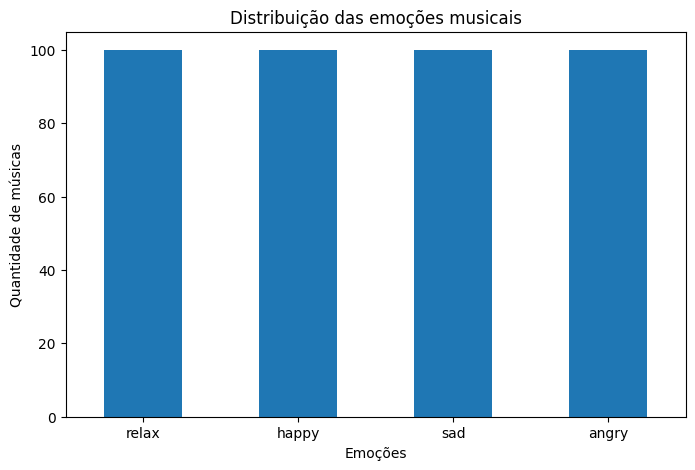

In [27]:
contagem = df["Class"].value_counts()

contagem.plot(kind="bar", figsize=(8,5))

plt.xlabel("Emoções")
plt.ylabel("Quantidade de músicas")
plt.title("Distribuição das emoções musicais")
plt.xticks(rotation=0)
plt.show()


####Transformação das linhas
Foi realizada a remoção de registros duplicados utilizando o método drop_duplicates(). Essa transformação eliminou 12 registros repetidos, reduzindo a base de 400 para 388 linhas e evitando que informações duplicadas inlfuenciassem o treinamento e a avaliação do modelo.



In [28]:
total_original = len(df)

df = df.drop_duplicates()

total_final = len(df)

excluidas = total_original - total_final

print("Total de linhas excluídas: ", excluidas)

Total de linhas excluídas:  12


Padronização dos valores das colunas

In [29]:
# Separar as características musicais
X = df.drop(columns=["Class"])

y = df["Class"]

print("Quantidade de características:", X.shape[1])
print("Quantidade de emoções:", y.shape[0])



Quantidade de características: 50
Quantidade de emoções: 388


####Transformação das colunas
Foi aplicada a técnica de padronização utilizando o StandardScaler, transformando as variáveis numéricas para uma escala comparável. Essa etapa é importante para o algoritmo KNN, pois evita que atributos com valores numericamente maiores tenha influência desproporcional no cálculo das distâncias

Vamos preparar os dados para o treinamento, dividindo a base em três partes: treinamento (70%), validação (15%) e teste (15%). O conjunto de treinamento será utilizado para ensinar o modelo, o de validação para comparar os parâmetros e o de teste para avaliar o desempenho final.


In [30]:
#Separar 70% para treinamento e 30% para validação e teste
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

#Dividir os 30% restantes em validação e teste
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Quantidade de dados de treinamento:", X_treino.shape[0])
print("Quantidade de dados de validação:", X_validacao.shape[0])
print("Quantidade de dados de teste:", X_teste.shape[0])

Quantidade de dados de treinamento: 271
Quantidade de dados de validação: 58
Quantidade de dados de teste: 59


In [31]:
scaler = StandardScaler()

X_treino = scaler.fit_transform(X_treino)
X_validacao = scaler.transform(X_validacao)
X_teste = scaler.transform(X_teste)

print("Padronização concluída!")

Padronização concluída!


Treinamento do Modelo Machine Learning


In [32]:
#Criar o modelo KNN com 5 vizinhos
modelo = KNeighborsClassifier(n_neighbors=5)

#Treinar o modelo com os dados de treinamento
modelo.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [33]:
# Realizar previsões com os dados de validação
previsoes = modelo.predict(X_validacao)

# Calcular a acurácia do modelo
from sklearn.metrics import accuracy_score

acuracia = accuracy_score(y_validacao, previsoes)

print("Acurácia do modelo:", acuracia * 100, "%")

Acurácia do modelo: 70.6896551724138 %


Testando diferentes quantidades de vizinhos


Em vez de criar oito modelos manualmente, ele percorre os valores de k, treina um modelo para cada quantidade de vizinhos e calcula sua acurácia


In [34]:
# from sklearn.neighbors import KNeighborsClassifier
# from sklearn.metrics import accuracy_score

# Quantidade de vizinhos que vamos testar
valores_k = [1, 3, 5, 7, 9, 11, 13, 15]

resultados = []

for k in valores_k:
  # Criar o modelo KNN com o valor de k
  modelo = KNeighborsClassifier(n_neighbors=k)

  # Treinar o modelo com os dados de treinamento
  modelo.fit(X_treino, y_treino)

  # Realizar previsões com os dados de validação
  previsoes = modelo.predict(X_validacao)

  # Calcular a acurácia do modelo
  acuracia = accuracy_score(y_validacao, previsoes)

  resultados.append((k, acuracia))

  print(f"K = {k} | Acurácia: {acuracia * 100:.2f}%")

K = 1 | Acurácia: 74.14%
K = 3 | Acurácia: 72.41%
K = 5 | Acurácia: 70.69%
K = 7 | Acurácia: 70.69%
K = 9 | Acurácia: 72.41%
K = 11 | Acurácia: 67.24%
K = 13 | Acurácia: 70.69%
K = 15 | Acurácia: 70.69%


In [35]:
# Identificar a quantidade de vizinhos com maior acurácia

melhor_k, melhor_acuracia = max(resultados, key=lambda x: x[1])

print(f"Melhor quantidade de vizinhos: {melhor_k}")
print(f"Melhor acurácia: {melhor_acuracia * 100:.2f}%")

Melhor quantidade de vizinhos: 1
Melhor acurácia: 74.14%


In [36]:
#Criar o modelo KNN com a melhor quantidade de vizinhos
modelo_final = KNeighborsClassifier(n_neighbors=melhor_k)

#Treinar o modelo com os dados de treinamento
modelo_final.fit(X_treino, y_treino)

KNeighborsClassifier(n_neighbors=1)

In [37]:
#Realizar previsões
previsoes_teste = modelo_final.predict(X_teste)

print("Previsões realizadas!")

Previsões realizadas!


In [38]:
#Calcular a acurácia do modelo
acuracia_teste = accuracy_score(y_teste, previsoes_teste)

print("Acurácia do modelo final:", round(acuracia_teste * 100, 2), "%")

Acurácia do modelo final: 66.1 %


####Gerando a Matriz de Confusão

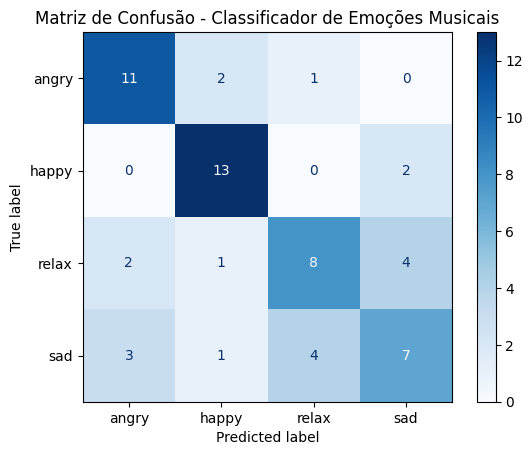

In [39]:
#Criar a matriz de confusão
matriz = confusion_matrix(y_teste, previsoes_teste, labels=["angry", "happy", "relax", "sad"])

#Exibir a matriz
visualizacao = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["angry", "happy", "relax", "sad"])
visualizacao.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão - Classificador de Emoções Musicais")
plt.show()



In [40]:
#Realizando uma previsão

#Selecionar a primeira música do conjunto de teste
musica = X_teste[0].reshape(1, -1) #organiza os dados no formato que o modelo espera receber

emocao_real = y_teste.iloc[0] #recupera a emoção verdadeira dessa música

print("Música selecionada!")
print("Emoção real:", emocao_real)

Música selecionada!
Emoção real: sad


In [41]:
#Prever a emoção da música
previsao = modelo_final.predict(musica)

print("Emoção prevista pelo modelo:", previsao[0])
print("Emoção real:", emocao_real)

if previsao[0] == emocao_real:
  print("Resultado: O modelo acertou!")
else:
  print("Resultado: O modelo errou!")

Emoção prevista pelo modelo: relax
Emoção real: sad
Resultado: O modelo errou!
